# 01. Exploração dos dados

Dataset *Diabetes 130-US hospitals* (UCI, 1999-2008). Cada linha é um atendimento hospitalar de um paciente diabético. O alvo do estudo é a readmissão em menos de 30 dias após a alta.

Este notebook usa o mesmo carregamento e a mesma coorte do treino (`src/data_loading.py`), para que o que se vê aqui seja o que o modelo recebe.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loading import (
    DEATH_OR_HOSPICE_DISCHARGE_IDS,
    GROUP_COLUMN,
    TARGET_COLUMN,
    build_cohort,
    load_raw_data,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

raw = load_raw_data(PROJECT_ROOT / "data" / "diabetic_data.csv")
cohort = build_cohort(raw)
TAXA_GERAL = cohort[TARGET_COLUMN].mean()
print(f"bruto: {raw.shape[0]} atendimentos, {raw.shape[1]} colunas")
print(f"coorte: {cohort.shape[0]} atendimentos, {cohort[GROUP_COLUMN].nunique()} pacientes")
print(f"taxa de readmissão em <30 dias na coorte: {TAXA_GERAL:.4f}")

bruto: 101766 atendimentos, 50 colunas
coorte: 99343 atendimentos, 69990 pacientes
taxa de readmissão em <30 dias na coorte: 0.1139


## Alvo

A coluna original `readmitted` tem três valores. Só `<30` conta como positivo.

readmitted
NO    0.539
>30   0.349
<30   0.112


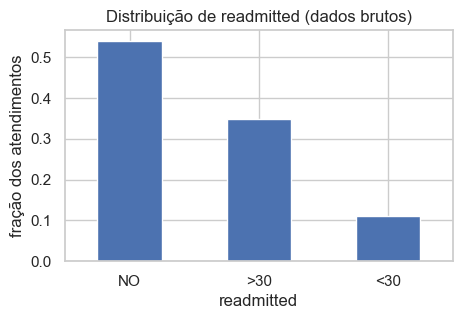

In [2]:
alvo = raw["readmitted"].value_counts(normalize=True)
print(alvo.to_string())
ax = alvo.plot.bar(figsize=(5, 3), rot=0, title="Distribuição de readmitted (dados brutos)")
ax.set_ylabel("fração dos atendimentos")
plt.show()

## Valores ausentes

`?` e `Unknown/Invalid` são os marcadores de ausência do dataset. `None` em `A1Cresult` e `max_glu_serum` não é ausência: significa que o exame não foi feito.

weight              0.969
medical_specialty   0.491
payer_code          0.396
race                0.022
diag_3              0.014
diag_2              0.004
diag_1              0.000
gender              0.000

fração com exame não realizado:
A1Cresult       0.833
max_glu_serum   0.947


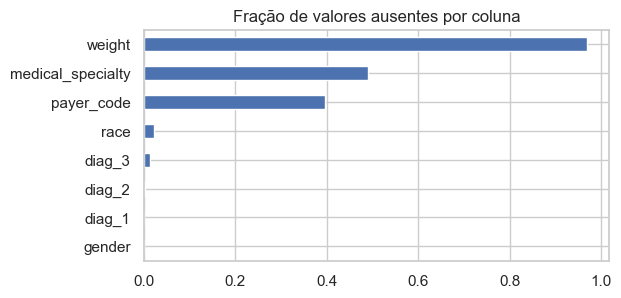

In [3]:
ausentes = raw.isna().mean().loc[lambda s: s > 0].sort_values(ascending=False)
print(ausentes.to_string())
nao_medido = (raw[["A1Cresult", "max_glu_serum"]] == "None").mean()
print("\nfração com exame não realizado:")
print(nao_medido.to_string())
ax = ausentes.plot.barh(figsize=(6, 3), title="Fração de valores ausentes por coluna")
ax.invert_yaxis()
plt.show()

## Atendimentos por paciente

Vários pacientes aparecem mais de uma vez. Por isso a divisão treino/teste é feita por paciente.

In [4]:
por_paciente = cohort[GROUP_COLUMN].value_counts()
distribuicao = por_paciente.clip(upper=5).value_counts().sort_index()
distribuicao.index = [str(i) if i < 5 else "5+" for i in distribuicao.index]
print(distribuicao.to_string())
print(f"\npacientes com mais de um atendimento: {(por_paciente > 1).mean():.3f}")
print(f"atendimentos que pertencem a esses pacientes: {cohort[GROUP_COLUMN].map(por_paciente).gt(1).mean():.3f}")

n_atend = cohort[GROUP_COLUMN].map(por_paciente).clip(upper=5)
taxa_n = cohort.groupby(n_atend)[TARGET_COLUMN].agg(n="size", taxa="mean")
print("\ntaxa de readmissão por número de atendimentos do paciente no dataset:")
print(taxa_n.to_string())

1     53649
2     10218
3      3233
4      1354
5+     1536

pacientes com mais de um atendimento: 0.233
atendimentos que pertencem a esses pacientes: 0.460

taxa de readmissão por número de atendimentos do paciente no dataset:
                 n  taxa
patient_nbr             
1            53649 0.043
2            20436 0.152
3             9699 0.194
4             5416 0.215
5            10143 0.283


## Altas por óbito ou hospice

Esses atendimentos saem da coorte, porque o paciente quase não tem como ser readmitido.

In [5]:
excluido = raw["discharge_disposition_id"].isin(DEATH_OR_HOSPICE_DISCHARGE_IDS)
resumo = (raw["readmitted"] == "<30").groupby(excluido).agg(n="size", taxa="mean")
resumo.index = ["mantidos", "óbito/hospice (excluídos)"]
print(resumo.to_string())

                               n  taxa
mantidos                   99343 0.114
óbito/hospice (excluídos)   2423 0.018


## Taxa de readmissão por variável

A linha tracejada é a taxa geral da coorte. Grupos com menos de 200 atendimentos ficam de fora.


Internações no ano anterior (number_inpatient)
                      n  taxa
number_inpatient             
0                 66245 0.086
1                 18984 0.133
2                  7300 0.179
3                  3271 0.210
4                  1574 0.241
5+                 1969 0.371

Emergências no ano anterior (number_emergency)
                      n  taxa
number_emergency             
0                 88249 0.107
1                  7474 0.147
2                  1984 0.188
3                   706 0.208
4+                  930 0.287



Faixa etária (age)
              n  taxa
age                  
[10-20)     690 0.058
[20-30)    1649 0.143
[30-40)    3764 0.113
[40-50)    9607 0.107
[50-60)   17060 0.098
[60-70)   22059 0.113
[70-80)   25331 0.121
[80-90)   16434 0.126
[90-100)   2589 0.119



Dias de internação (time_in_hospital)
                      n  taxa
time_in_hospital             
1                 13824 0.084
2                 16891 0.101
3                 17432 0.108
4                 13684 0.120
5                  9749 0.123
6                  7355 0.129
7                  5696 0.131
8                  4271 0.146
9                  2879 0.143
10                 2262 0.148
11                 1770 0.108
12                 1383 0.140
13                 1152 0.129
14                  995 0.135

Resultado de A1C (A1Cresult)
               n  taxa
A1Cresult             
>7          3775 0.101
>8          8137 0.099
None       82509 0.117
Norm        4922 0.098

Número de diagnósticos (number_diagnoses)
                      n  taxa
number_diagnoses             
1                   219 0.059
2                  1021 0.061
3                  2824 0.074
4                  5499 0.083
5                 11301 0.092
6                  9986 0.105
7                 10215 0.109


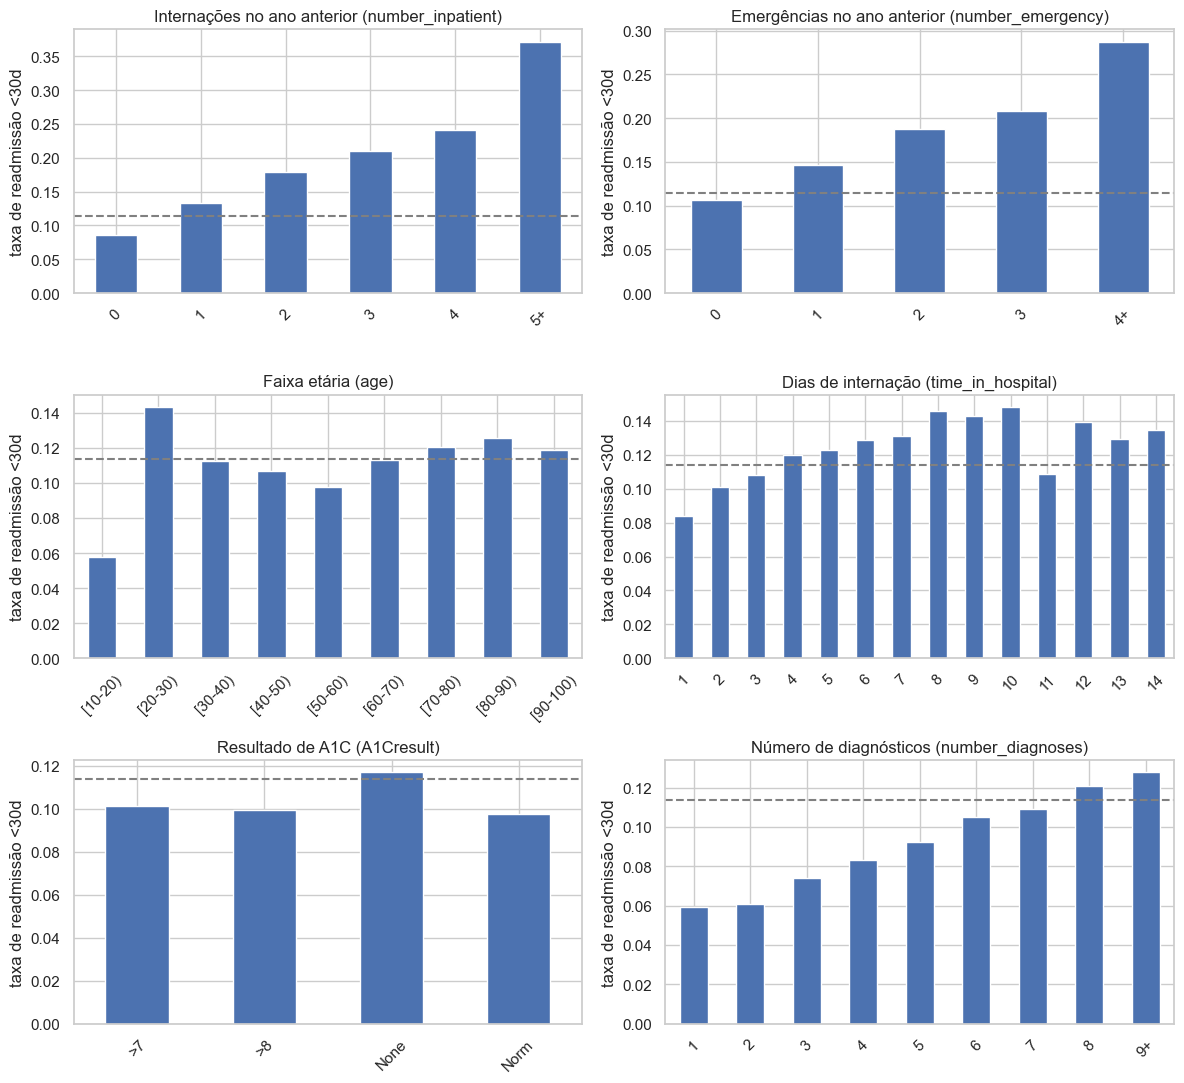

In [6]:
def taxa_por(serie, minimo=200):
    tabela = cohort.groupby(serie, dropna=False)[TARGET_COLUMN].agg(n="size", taxa="mean")
    return tabela[tabela["n"] >= minimo]


def grafico_taxa(tabela, titulo, ax):
    tabela["taxa"].plot.bar(ax=ax, rot=45, title=titulo)
    ax.axhline(TAXA_GERAL, linestyle="--", color="gray")
    ax.set_xlabel("")
    ax.set_ylabel("taxa de readmissão <30d")


def agrupar_acima(serie, teto):
    """Junta os valores a partir de `teto` em um único grupo rotulado, por exemplo "5+"."""
    return serie.clip(upper=teto).map(lambda v: f"{teto}+" if v == teto else str(v))


paineis = {
    "Internações no ano anterior (number_inpatient)": agrupar_acima(cohort["number_inpatient"], 5),
    "Emergências no ano anterior (number_emergency)": agrupar_acima(cohort["number_emergency"], 4),
    "Faixa etária (age)": cohort["age"],
    "Dias de internação (time_in_hospital)": cohort["time_in_hospital"],
    "Resultado de A1C (A1Cresult)": cohort["A1Cresult"],
    "Número de diagnósticos (number_diagnoses)": agrupar_acima(cohort["number_diagnoses"], 9),
}
fig, axes = plt.subplots(3, 2, figsize=(12, 11))
for (titulo, serie), ax in zip(paineis.items(), axes.ravel()):
    tabela = taxa_por(serie)
    print(f"\n{titulo}")
    print(tabela.to_string())
    grafico_taxa(tabela, titulo, ax)
fig.tight_layout()
plt.show()

### Destino da alta

`discharge_disposition_id` é um código. Os mais comuns: 1 = casa, 3 = unidade de enfermagem especializada (SNF), 6 = casa com cuidado domiciliar, 18 = não informado, 2 = outro hospital de curta permanência, 22 = reabilitação, 5 = outra instituição de internação.

                              n  taxa
discharge_disposition_id             
22                         1993 0.277
5                          1184 0.209
2                          2128 0.161
3                         13954 0.147
7                           623 0.144
4                           815 0.128
6                         12902 0.127
18                         3691 0.124
25                          989 0.093
1                         60234 0.093
23                          412 0.073


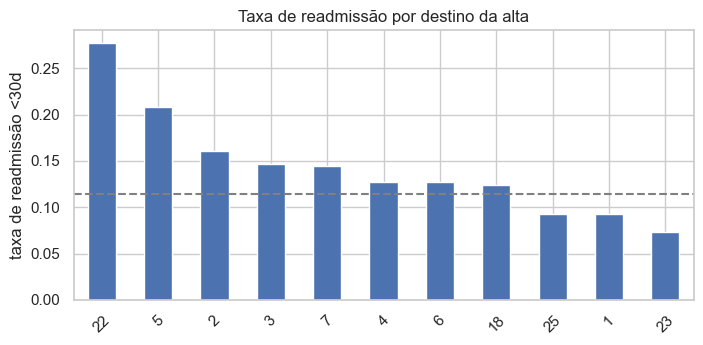

In [7]:
destino = taxa_por(cohort["discharge_disposition_id"]).sort_values("taxa", ascending=False)
print(destino.to_string())
fig, ax = plt.subplots(figsize=(8, 3.5))
grafico_taxa(destino, "Taxa de readmissão por destino da alta", ax)
plt.show()

### Medicação

In [8]:
for coluna in ["diabetesMed", "change", "insulin"]:
    print(f"\n{coluna}")
    print(taxa_por(cohort[coluna]).to_string())


diabetesMed
                 n  taxa
diabetesMed             
No           22624 0.099
Yes          76719 0.118

change
            n  taxa
change             
Ch      46122 0.120
No      53221 0.108

insulin
             n  taxa
insulin             
Down     11908 0.142
No       46379 0.102
Steady   30069 0.114
Up       10987 0.133


## O que os dados mostram

- **Alvo raro.** 11,2% dos atendimentos brutos e 11,4% da coorte são readmissões em menos de 30 dias. Acurácia não serve como métrica.
- **Colunas quase vazias.** `weight` está ausente em 96,9% das linhas e `payer_code` em 39,6%, e ficam fora do modelo. `medical_specialty` falta em 49,1% e entra com a categoria `missing`.
- **Exames raramente feitos.** A1C não foi medido em 83,3% dos atendimentos e a glicose sérica em 94,7%. A taxa de readmissão é de 11,7% sem A1C e perto de 10% com A1C medido, uma diferença pequena.
- **Pacientes repetidos.** 23,3% dos pacientes têm mais de um atendimento e respondem por 46,0% das linhas. Uma divisão aleatória por linha poria o mesmo paciente em treino e teste.
- **Cuidado com contagens do próprio dataset.** A taxa vai de 4,3% em pacientes com um único atendimento a 28,3% nos que têm cinco ou mais. Parte disso é mecânica: quem foi readmitido tem, por definição, outro atendimento no dataset. Esse número não pode virar atributo, porque usa informação do futuro.
- **Óbito e hospice.** Nos 2.423 atendimentos excluídos a taxa é de 1,8%, contra 11,4% nos mantidos.
- **Histórico é o sinal mais forte.** A taxa sobe de 8,6% sem internações no ano anterior para 37,1% com cinco ou mais, e de 10,7% sem emergências para 28,7% com quatro ou mais.
- **Destino da alta pesa.** Alta para reabilitação (código 22) tem 27,7% de readmissão e para outra instituição de internação (código 5) tem 20,9%. Alta para casa (código 1) tem 9,3%.
- **Sinais mais fracos.** A taxa cresce com os dias de internação (8,4% com um dia, cerca de 14,6% entre oito e dez) e com o número de diagnósticos (5,9% com um, 12,8% com nove ou mais). Idade separa pouco: entre 9,8% e 12,6% dos 30 aos 100 anos. Mudança na dose de insulina vem com taxa maior (14,2% ao reduzir, 13,3% ao aumentar, 10,2% sem insulina).

São associações observadas nos dados, não efeitos causais.